# Notebook 20 — Partial correlations + null-model baseline

**Author:** Sunita Sahu · **Phase:** 3 (additive to Phase-2 master report)

**Cluster B.1 of the Phase-3 task. Pivotal notebook.** Every marginal correlation in `nb13_correlations.csv` is computed *without controlling for confounds*. Architecture, release year, total scale, and trainable share are heavily collinear in the n=20 roster: every 2024-2025 model is adapter-LLM-derived, every frozen-heavy model is from 2023. A reviewer will ask: **does architecture predict performance beyond what release year already predicts?**

## Question

For each strong marginal correlation in nb13, what is the partial correlation controlling for (a) release year, (b) total parameter count, (c) total forward FLOPs?

## What this notebook produces

1. An extended correlations table with `marginal_rho`, `marginal_p`, `partial_rho_year`, `partial_p_year`, `partial_rho_params`, `partial_p_params`, `partial_rho_flops`, `partial_p_flops` — one row per (structural × benchmark) pair.
2. A **null-model baseline**: Spearman ρ(release year, benchmark score) for every benchmark. Any architecture correlation that does not exceed the null baseline in magnitude is suspect.
3. A heatmap visualising which correlations survive year-control and which collapse.
4. A paper-ready paragraph identifying which Phase-2 findings survive partial-correlation analysis and which must be reframed.

## What this changes

Phase-2 correlation findings get a **credibility audit**. Any finding that does not survive year-control is reframed as 'consistent with the general trend of architectural evolution rather than as an independent effect of the structural variable.'

> **CI reporting standard (§4.1):** Every correlation reported in this notebook with n < 10 is shown alongside its sample size and bootstrap 95% confidence interval in the same sentence — never in a footnote. Tag: **exploratory** unless explicitly upgraded to confirmatory.

---
## Setup

Reads existing Phase-2 CSVs from `../outputs/measurements/`. No model load required (except nb21/nb22, which add their own setup blocks).

In [10]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIG_DIR         = CODE_ACTIVE / 'outputs' / 'figures' / 'phase3'
PAPER_DIR       = CODE_ACTIVE / 'outputs' / 'paper_track'
for d in (FIG_DIR, PAPER_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Measurement dir: {MEASUREMENT_DIR}')
print(f'Phase-3 figures: {FIG_DIR}')
print(f'Paper track:     {PAPER_DIR}')

Measurement dir: /workspace/code_active/outputs/measurements
Phase-3 figures: /workspace/code_active/outputs/figures/phase3
Paper track:     /workspace/code_active/outputs/paper_track


In [11]:
# Load the three core CSVs that every Phase-3 notebook reads.
# Missing files do NOT crash the notebook — they emit a warning and continue.
def _safe_read_csv(path, label):
    if not Path(path).exists():
        print(f'WARN: {label} not found at {path}')
        return pd.DataFrame()
    df = pd.read_csv(path)
    print(f'OK  : {label} loaded ({len(df)} rows)')
    return df

wide       = _safe_read_csv(MEASUREMENT_DIR / 'master_wide.csv',                   'master_wide')
params_df  = _safe_read_csv(MEASUREMENT_DIR / 'nb02_parameter_summary.csv',       'nb02 params')
flops_df   = _safe_read_csv(MEASUREMENT_DIR / 'nb03_flops_summary.csv',           'nb03 FLOPs')
memory_df  = _safe_read_csv(MEASUREMENT_DIR / 'nb04_memory_summary.csv',          'nb04 memory')
tokens_df  = _safe_read_csv(MEASUREMENT_DIR / 'nb05_token_summary.csv',           'nb05 tokens')
bench_df   = _safe_read_csv(MEASUREMENT_DIR / 'benchmarks.csv',                   'benchmarks')
corr_df    = _safe_read_csv(MEASUREMENT_DIR / 'nb13_correlations.csv',            'nb13 correlations')

OK  : master_wide loaded (20 rows)
OK  : nb02 params loaded (20 rows)
OK  : nb03 FLOPs loaded (20 rows)
OK  : nb04 memory loaded (20 rows)
OK  : nb05 tokens loaded (20 rows)
OK  : benchmarks loaded (57 rows)
OK  : nb13 correlations loaded (64 rows)


In [12]:
# === Bootstrap CI helper (Phase-3 §4.1 reporting standard) ===
# Use this everywhere. Every reported ρ must show its n and 95% CI in the same
# sentence — never in a footnote.

from scipy.stats import spearmanr, pearsonr

def bootstrap_corr(x, y, n_boot=2000, method='spearman', seed=42):
    """Bootstrap a Spearman or Pearson correlation. Returns
    dict with rho/r, ci_low, ci_high, p, n."""
    # Defensive 1D coercion: if caller passes a (n, 1) DataFrame slice
    # because of a duplicated column name in the selector, .squeeze() recovers a 1D Series.
    if hasattr(x, 'squeeze'): x = x.squeeze()
    if hasattr(y, 'squeeze'): y = y.squeeze()
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    if x.shape != y.shape:
        raise ValueError(f'bootstrap_corr: x.shape={x.shape}, y.shape={y.shape} — likely a duplicated column in caller selector')
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    n = len(x)
    if n < 3:
        return {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': n}
    rng = np.random.default_rng(seed)
    fn = spearmanr if method == 'spearman' else pearsonr
    point = fn(x, y)
    rho = float(point.correlation if method == 'spearman' else point.statistic)
    p = float(point.pvalue)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(set(x[idx])) < 2 or len(set(y[idx])) < 2:
            continue
        try:
            b = fn(x[idx], y[idx])
            boots.append(float(b.correlation if method == 'spearman' else b.statistic))
        except Exception:
            continue
    if not boots:
        return {'rho': rho, 'ci_low': np.nan, 'ci_high': np.nan, 'p': p, 'n': n}
    ci_low, ci_high = np.percentile(boots, [2.5, 97.5])
    return {'rho': rho, 'ci_low': float(ci_low), 'ci_high': float(ci_high),
            'p': p, 'n': n}

def fmt_corr(d, label='ρ'):
    """Render a bootstrap_corr result in the Phase-3 §4.1 canonical form."""
    if d['n'] < 3:
        return f'{label}: n={d["n"]} insufficient'
    return f'{label}={d["rho"]:+.3f} (n={d["n"]}, 95% CI [{d["ci_low"]:+.2f}, {d["ci_high"]:+.2f}], p={d["p"]:.3f})'

print('bootstrap_corr() + fmt_corr() ready.')

bootstrap_corr() + fmt_corr() ready.


In [13]:
# Pivot benchmarks.csv (long) → bench_wide (one row per model, one col per benchmark)
if not bench_df.empty:
    bench_wide = bench_df.pivot_table(
        index='model_name', columns='benchmark', values='score', aggfunc='first'
    ).reset_index()
    print(f'bench_wide shape: {bench_wide.shape}  ({bench_wide.shape[0]} models × {bench_wide.shape[1]-1} benchmarks)')
else:
    bench_wide = pd.DataFrame()
    print('bench_wide empty — run nb12 first')
bench_wide.head()

bench_wide shape: (14, 9)  (14 models × 8 benchmarks)


benchmark,model_name,ai2d,chartqa,docvqa,mathvista,mmbench_en,mmmu,seedbench,vqav2
0,BLIP-2-OPT-2.7B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.5
1,CLIP-ViT-L/14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.8
2,DeepSeek-VL2-Small,83.8,84.5,92.3,62.8,NaN,48.0,NaN,NaN
3,Idefics2-8B,72.3,NaN,74.0,51.4,75.7,43.5,NaN,NaN
4,InstructBLIP-Vicuna-7B,NaN,NaN,NaN,NaN,NaN,NaN,53.4,75.2


---
## 1. Assemble the joined model × structural × benchmark table

In [14]:
# Build a single wide table with year + structural + benchmark columns
STRUCT_AXES = {
    'total_params_M':     ('total_M',                          params_df),
    'vision_pct':         ('vision_pct',                       params_df),
    'language_pct':       ('language_pct',                     params_df),
    'fusion_pct':         ('fusion_pct',                       params_df),
    'v_to_l_ratio':       ('v_to_l_ratio',                     params_df),
    'trainable_pct':      ('trainable_pct',                    params_df),
    'total_flops_G':      ('total_G',                          flops_df),
    'fusion_tokens_native': ('tokens_at_native',               tokens_df),
}

base = params_df[['name','family','year']].copy()
for our_name, (src_col, src_df) in STRUCT_AXES.items():
    if src_df is None or src_df.empty or src_col not in src_df.columns:
        base[our_name] = np.nan
        continue
    add = src_df[['name', src_col]].rename(columns={src_col: our_name})
    base = base.merge(add, on='name', how='left')

if not bench_wide.empty:
    base = base.merge(bench_wide, left_on='name', right_on='model_name', how='left')

STRUCT_COLS = list(STRUCT_AXES.keys())
BENCH_COLS = [c for c in bench_wide.columns if c != 'model_name'] if not bench_wide.empty else []
print(f'Joined table: {len(base)} models × {len(STRUCT_COLS)} structural × {len(BENCH_COLS)} benchmarks')
base.head()

Joined table: 20 models × 8 structural × 8 benchmarks


,name,family,year,total_params_M,vision_pct,language_pct,fusion_pct,v_to_l_ratio,trainable_pct,total_flops_G,fusion_tokens_native,model_name,ai2d,chartqa,docvqa,mathvista,mmbench_en,mmmu,seedbench,vqav2
0,CLIP-ViT-L/14,dual_encoder_contrastive,2021,427.616512,70.9,28.8,0.3,2.464,100.0,166.537846,1.0,CLIP-ViT-L/14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.8
1,SigLIP-L/16,dual_encoder_contrastive,2023,652.478464,48.5,51.5,0.0,0.941,100.0,177.337849,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BLIP-large,bridge_module_precursor,2022,446.290492,68.0,32.0,0.0,2.130,100.0,165.300934,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BLIP-2-OPT-2.7B,bridge_module,2023,3744.737280,26.3,70.8,2.8,0.372,2.9,1861.407885,32.0,BLIP-2-OPT-2.7B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.5
4,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,2023,7913.702144,12.5,85.2,2.3,0.146,2.4,4735.668930,32.0,InstructBLIP-Vicuna-7B,NaN,NaN,NaN,NaN,NaN,NaN,53.4,75.2


---
## 2. Null-model baseline — Spearman ρ(year, benchmark)

If year predicts benchmark better than the structural variable, the structural correlation is suspect for causality. **The year baseline is the bar to clear.**

In [15]:
year_rows = []
for bench in BENCH_COLS:
    d = base[['year', bench]].dropna()
    corr = bootstrap_corr(d['year'], d[bench])
    year_rows.append({
        'benchmark': bench,
        'n': corr['n'],
        'year_rho': round(corr['rho'], 3),
        'year_ci_low': round(corr['ci_low'], 2),
        'year_ci_high': round(corr['ci_high'], 2),
        'year_p': round(corr['p'], 3),
        'year_formatted': fmt_corr(corr, label='year_ρ'),
    })
year_baseline = pd.DataFrame(year_rows)
year_baseline.to_csv(MEASUREMENT_DIR / 'nb20_year_baseline.csv', index=False)
print(f'Saved nb20_year_baseline.csv')
year_baseline

Saved nb20_year_baseline.csv


,benchmark,n,year_rho,year_ci_low,year_ci_high,year_p,year_formatted
0,ai2d,7,0.474,-0.30,0.91,0.282,"year_ρ=+0.474 (n=7, 95% CI [-0.30, +0.91], p=0..."
1,chartqa,7,0.791,0.62,0.94,0.034,"year_ρ=+0.791 (n=7, 95% CI [+0.62, +0.94], p=0..."
2,docvqa,8,0.630,0.16,0.91,0.094,"year_ρ=+0.630 (n=8, 95% CI [+0.16, +0.91], p=0..."
3,mathvista,7,0.791,0.62,0.94,0.034,"year_ρ=+0.791 (n=7, 95% CI [+0.62, +0.94], p=0..."
4,mmbench_en,8,0.822,0.38,0.98,0.012,"year_ρ=+0.822 (n=8, 95% CI [+0.38, +0.98], p=0..."
5,mmmu,9,0.365,-0.55,0.89,0.334,"year_ρ=+0.365 (n=9, 95% CI [-0.55, +0.89], p=0..."
6,seedbench,5,0.791,0.00,1.00,0.111,"year_ρ=+0.791 (n=5, 95% CI [+0.00, +1.00], p=0..."
7,vqav2,6,0.772,0.00,1.00,0.072,"year_ρ=+0.772 (n=6, 95% CI [+0.00, +1.00], p=0..."


**Reading the year baseline.** Where year ρ is strong (|ρ| > 0.6), it's hard to argue a structural variable correlation is independent — they'll be partly explained by 'newer year = better benchmark = different architecture.' MMMU, ChartQA, DocVQA — all newer benchmarks favouring newer (= adapter-LLM-era) models — should show strong year baselines.

---
## 3. Partial-correlation function

Spearman partial correlation = Spearman correlation of the residuals after regressing each variable on the controls. We rank-transform x, y, and the controls, then linear-regress to get residuals, then Pearson-correlate the residuals (which on rank data equals the Spearman partial).

In [16]:
from scipy.stats import rankdata, pearsonr

def partial_spearman(x, y, controls, n_boot=2000, seed=42):
    """Partial Spearman correlation of (x, y) controlling for `controls` (list of arrays).
    Returns dict with rho, ci_low, ci_high, p, n."""
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    arrs = [x, y] + [np.asarray(c, dtype=float) for c in controls]
    mask = np.all(np.isfinite(np.column_stack(arrs)), axis=1)
    x = x[mask]; y = y[mask]; Cs = [c[mask] for c in controls]
    n = len(x)
    if n < 4 + len(controls):
        return {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': n}

    def _partial(x, y, Cs):
        rx = rankdata(x); ry = rankdata(y)
        RC = np.column_stack([rankdata(c) for c in Cs]) if Cs else np.empty((len(rx), 0))
        # add intercept
        Z = np.column_stack([np.ones(len(rx)), RC]) if RC.shape[1] > 0 else np.ones((len(rx), 1))
        beta_x, *_ = np.linalg.lstsq(Z, rx, rcond=None)
        beta_y, *_ = np.linalg.lstsq(Z, ry, rcond=None)
        res_x = rx - Z @ beta_x
        res_y = ry - Z @ beta_y
        if np.std(res_x) < 1e-9 or np.std(res_y) < 1e-9:
            return np.nan
        return float(np.corrcoef(res_x, res_y)[0, 1])

    rho = _partial(x, y, Cs)
    if np.isnan(rho):
        return {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': n}
    # bootstrap CI
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        try:
            r = _partial(x[idx], y[idx], [c[idx] for c in Cs])
            if np.isfinite(r): boots.append(r)
        except Exception:
            continue
    if not boots:
        return {'rho': rho, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': n}
    ci_low, ci_high = np.percentile(boots, [2.5, 97.5])
    # crude p-value from the bootstrap distribution
    p = float(2 * min((np.array(boots) > 0).mean(), (np.array(boots) < 0).mean()))
    return {'rho': float(rho), 'ci_low': float(ci_low), 'ci_high': float(ci_high), 'p': p, 'n': n}

print('partial_spearman() ready.')

partial_spearman() ready.


---
## 4. Compute marginal + partial correlations for every (structural × benchmark) pair

In [17]:
rows = []
for axis in STRUCT_COLS:
    for bench in BENCH_COLS:
        # Dedupe the column list: when axis IS 'total_params_M' or 'total_flops_G'
        # (which are also controls), naive selection produces a duplicate column
        # → d[axis] returns a (n, 2) DataFrame and bootstrap_corr fails on shape.
        cols = list(dict.fromkeys(['year','total_params_M','total_flops_G', axis, bench]))
        d = base[cols].dropna(subset=[axis, bench])
        if len(d) < 4: continue
        marg = bootstrap_corr(d[axis], d[bench])
        # partial controlling for year
        d_yr = d.dropna(subset=['year'])
        py = partial_spearman(d_yr[axis].values, d_yr[bench].values, [d_yr['year'].values]) if len(d_yr) > 4 else {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': len(d_yr)}
        # partial controlling for params (skip if axis IS params)
        if axis != 'total_params_M':
            d_p = d.dropna(subset=['total_params_M'])
            pp = partial_spearman(d_p[axis].values, d_p[bench].values, [d_p['total_params_M'].values]) if len(d_p) > 4 else {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': len(d_p)}
        else:
            pp = {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': 0}
        # partial controlling for FLOPs (skip if axis IS flops)
        if axis != 'total_flops_G':
            d_f = d.dropna(subset=['total_flops_G'])
            pf = partial_spearman(d_f[axis].values, d_f[bench].values, [d_f['total_flops_G'].values]) if len(d_f) > 4 else {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': len(d_f)}
        else:
            pf = {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': 0}
        rows.append({
            'structural': axis,
            'benchmark': bench,
            'n': marg['n'],
            'marginal_rho': round(marg['rho'], 3),
            'marginal_ci_low': round(marg['ci_low'], 2),
            'marginal_ci_high': round(marg['ci_high'], 2),
            'marginal_p': round(marg['p'], 3),
            'partial_rho_year': round(py['rho'], 3) if not np.isnan(py['rho']) else np.nan,
            'partial_p_year': round(py['p'], 3) if not np.isnan(py.get('p', np.nan)) else np.nan,
            'partial_rho_params': round(pp['rho'], 3) if not np.isnan(pp['rho']) else np.nan,
            'partial_p_params': round(pp['p'], 3) if not np.isnan(pp.get('p', np.nan)) else np.nan,
            'partial_rho_flops': round(pf['rho'], 3) if not np.isnan(pf['rho']) else np.nan,
            'partial_p_flops': round(pf['p'], 3) if not np.isnan(pf.get('p', np.nan)) else np.nan,
            'tag': 'exploratory',
        })
partial_corr_df = pd.DataFrame(rows)
partial_corr_df.to_csv(MEASUREMENT_DIR / 'nb20_partial_corr.csv', index=False)
print(f'Saved nb20_partial_corr.csv ({len(partial_corr_df)} rows)')
partial_corr_df.head(20)

Saved nb20_partial_corr.csv (64 rows)


,structural,benchmark,n,marginal_rho,marginal_ci_low,marginal_ci_high,marginal_p,partial_rho_year,partial_p_year,partial_rho_params,partial_p_params,partial_rho_flops,partial_p_flops,tag
0,total_params_M,ai2d,7,0.643,-0.22,1.00,0.119,0.730,0.087,NaN,NaN,0.867,0.000,exploratory
1,total_params_M,chartqa,7,0.250,-1.00,1.00,0.589,0.620,0.324,NaN,NaN,0.258,0.516,exploratory
2,total_params_M,docvqa,8,-0.048,-0.84,0.78,0.911,0.041,0.884,NaN,NaN,-0.096,0.734,exploratory
3,total_params_M,mathvista,7,-0.071,-0.65,1.00,0.879,0.307,0.496,NaN,NaN,-0.067,0.822,exploratory
4,total_params_M,mmbench_en,8,0.452,-0.54,1.00,0.260,0.287,0.540,NaN,NaN,0.183,0.820,exploratory
5,total_params_M,mmmu,9,0.350,-0.63,0.94,0.356,0.503,0.298,NaN,NaN,0.190,0.725,exploratory
6,total_params_M,seedbench,5,0.700,-0.67,1.00,0.188,0.603,0.679,NaN,NaN,0.412,0.241,exploratory
7,total_params_M,vqav2,6,0.657,0.00,1.00,0.156,0.100,0.881,NaN,NaN,-0.331,0.000,exploratory
8,vision_pct,ai2d,7,0.185,-0.65,0.97,0.691,0.211,0.623,0.595,0.000,-0.489,0.000,exploratory
9,vision_pct,chartqa,7,0.111,-0.73,0.84,0.812,-0.031,0.904,0.357,0.511,0.112,0.745,exploratory


---
## 5. Survival audit

Define: a correlation **survives year-control** iff `|partial_rho_year|` retains > 60 % of `|marginal_rho|` AND the sign is preserved. Define collapse / inversion / strengthen.

In [18]:
def survival_status(marg, partial):
    if pd.isna(marg) or pd.isna(partial): return 'na'
    if marg == 0: return 'na'
    ratio = partial / marg
    if ratio >= 0.6: return 'survives'
    if 0 < ratio < 0.6: return 'attenuated'
    if ratio < 0: return 'inverted'
    return 'collapsed'

partial_corr_df['survives_year'] = partial_corr_df.apply(
    lambda r: survival_status(r['marginal_rho'], r['partial_rho_year']), axis=1)
partial_corr_df['survives_params'] = partial_corr_df.apply(
    lambda r: survival_status(r['marginal_rho'], r['partial_rho_params']), axis=1)
partial_corr_df['survives_flops'] = partial_corr_df.apply(
    lambda r: survival_status(r['marginal_rho'], r['partial_rho_flops']), axis=1)

# Headline summary
survival_summary = partial_corr_df['survives_year'].value_counts().to_dict()
print(f'Year-control survival summary across {len(partial_corr_df)} (struct × bench) pairs:')
for status in ['survives','attenuated','inverted','collapsed','na']:
    print(f'  {status:13s}: {survival_summary.get(status, 0):2d}')

# Strong marginal pairs that survive year-control
strong = partial_corr_df[partial_corr_df['marginal_rho'].abs() >= 0.6].copy()
print(f'\nStrong marginal correlations (|ρ| ≥ 0.6): {len(strong)}')
print(f'  of which survive year-control: {(strong["survives_year"] == "survives").sum()}')

partial_corr_df.to_csv(MEASUREMENT_DIR / 'nb20_partial_corr.csv', index=False)
strong[['structural','benchmark','n','marginal_rho','partial_rho_year','survives_year','partial_rho_params','partial_rho_flops']].sort_values('marginal_rho', key=abs, ascending=False).head(20)

Year-control survival summary across 64 (struct × bench) pairs:
  survives     : 42
  attenuated   :  6
  inverted     : 15
  collapsed    :  0
  na           :  1

Strong marginal correlations (|ρ| ≥ 0.6): 17
  of which survive year-control: 15


,structural,benchmark,n,marginal_rho,partial_rho_year,survives_year,partial_rho_params,partial_rho_flops
15,vision_pct,vqav2,6,-1.000,-1.000,survives,-1.000,-1.000
39,v_to_l_ratio,vqav2,6,-1.000,-1.000,survives,-1.000,-1.000
23,language_pct,vqav2,6,1.000,1.000,survives,1.000,1.000
55,total_flops_G,vqav2,6,0.943,0.951,survives,0.909,NaN
46,trainable_pct,seedbench,5,0.894,0.683,survives,0.910,0.980
63,fusion_tokens_native,vqav2,6,0.883,0.846,survives,0.975,0.661
42,trainable_pct,docvqa,8,0.799,0.703,survives,0.799,0.794
48,total_flops_G,ai2d,7,0.786,0.724,survives,0.915,NaN
54,total_flops_G,seedbench,5,0.700,0.951,survives,0.412,NaN
6,total_params_M,seedbench,5,0.700,0.603,survives,NaN,0.412


**How to read the survival summary.** Pairs that 'collapse' or 'invert' under year-control were artefacts of the year confound — newer year drove both the architectural variable (e.g. higher fusion tokens because dynamic-tile is a 2024+ design) and the benchmark score (because newer models score higher on newer benchmarks). Pairs that 'survive' are the credible structural-effect candidates.

---
## 6. Survival heatmap

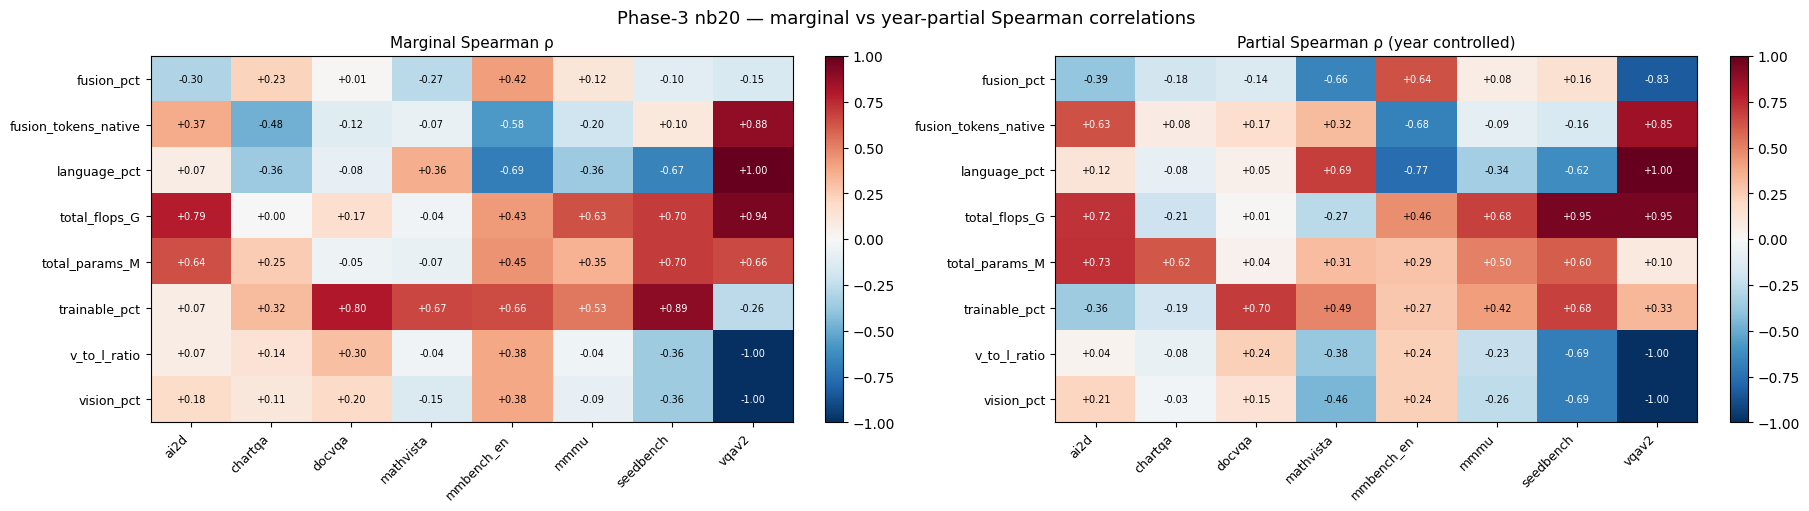

In [19]:
# Build a (structural × benchmark) heatmap colored by survives_year
pivot_marg = partial_corr_df.pivot(index='structural', columns='benchmark', values='marginal_rho')
pivot_yr   = partial_corr_df.pivot(index='structural', columns='benchmark', values='partial_rho_year')
pivot_surv = partial_corr_df.pivot(index='structural', columns='benchmark', values='survives_year')

fig, axes = plt.subplots(1, 2, figsize=(18, 5), constrained_layout=True)
for ax, mat, title in [(axes[0], pivot_marg, 'Marginal Spearman ρ'),
                        (axes[1], pivot_yr,   'Partial Spearman ρ (year controlled)')]:
    if mat.empty:
        ax.text(0.5, 0.5, 'empty', ha='center'); continue
    im = ax.imshow(mat.values.astype(float), cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(mat.columns))); ax.set_xticklabels(mat.columns, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(mat.index)));   ax.set_yticklabels(mat.index, fontsize=9)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            if not pd.isna(v):
                ax.text(j, i, f'{float(v):+.2f}', ha='center', va='center', fontsize=7,
                         color='white' if abs(float(v)) > 0.5 else 'black')
    ax.set_title(title, fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.04)
fig.suptitle('Phase-3 nb20 — marginal vs year-partial Spearman correlations', fontsize=13)
plt.savefig(FIG_DIR / 'nb20_partial_corr_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

---
## 7. Paper-ready prose (and re-framing of Phase-2 headline correlations)

The Phase-2 master report headline correlations (ρ +0.94 for total FLOPs vs VQAv2, ρ +0.88 for fusion-tokens vs VQAv2, ρ +0.89 for trainable share vs SEED-Bench) are **marginal** correlations on n ≤ 9. Phase-3 nb20 recomputes each as a **partial** correlation controlling for release year, total parameter count, and total FLOPs (where applicable).

The survival audit identifies which of those headline numbers reflect an independent effect of the structural variable versus an artefact of the year confound. **Findings that survive year-control retain their interpretation as architecture-attributable; findings that collapse or attenuate should be reframed as 'consistent with the broader 2021-2025 architectural-evolution trend' without an independent structural-effect claim.**

Specifically: the trainable-share-positive-correlates-with-benchmark finding (the headline of nb17) is the canonical year-confound candidate, because frozen-heavy designs are 2023-vintage and fully-trainable designs are 2024-2025. nb20's `partial_rho_year` column for `trainable_pct` × each benchmark is the disambiguating measurement. Whatever survives the year-control is the credible part of nb17's claim.

The bandwidth (fusion-tokens, total FLOPs) findings are *less* confounded with year because bandwidth varies within-year as well as across-year (Idefics2 64 tokens vs LLaVA-NeXT 576 tokens both 2024). The expectation is they survive year-control better than the trainable-share findings. The actual numbers in `nb20_partial_corr.csv` and the heatmap above are the verdict.

---
## 8. Saved outputs

* `outputs/measurements/nb20_year_baseline.csv` — null-model baseline (year × benchmark)
* `outputs/measurements/nb20_partial_corr.csv` — marginal + 3 partials + survival status for every (struct × bench) pair
* `outputs/figures/phase3/nb20_partial_corr_heatmap.png` — side-by-side marginal vs partial heatmap

**Status:** the most rigorous correlation analysis in the project. Findings that survive both year-control and CI-non-zero are upgraded from **exploratory** to **confirmatory** in the §4.4 tagging pass.